<img src="feature-selection.jpg" width="1100">

<img src="./feature-selection.ppm" width="1100">

### Feature selection methods categorized three main types:

1. **Filter Methods:**
   - These methods select features based on their statistical properties in relation to the target variable.
   - They are typically fast and independent of the learning algorithm.
   - Examples: correlation coefficient, chi-squared test, mutual information.

2. **Wrapper Methods:**
   - These methods use a predictive model to score feature subsets.
   - They can be computationally intensive but often provide the best performing feature set for that particular type of model.
   - Examples: recursive feature elimination, forward feature selection.

3. **Embedded Methods:**
   - These methods perform feature selection as part of the model training process.
   - They are generally faster than wrapper methods and less prone to overfitting.
   - Examples: Lasso, Ridge Regression, Decision Trees.

## Filter Methods for Feature Selection

### Correlation-based Selection

In [70]:
import numpy as np
import pandas as pd
from sklearn.datasets import load_wine

# Load the Boston Housing dataset
X, y = load_wine(return_X_y=True)
feature_names = load_wine().feature_names

df = pd.concat([pd.DataFrame(X), pd.Series(y)], axis=1)

df = pd.concat([pd.DataFrame(X, columns=feature_names), pd.Series(y, name="target")], axis=1)

In [71]:
df

,alcohol,malic_acid,ash,alcalinity_of_ash,magnesium,total_phenols,flavanoids,nonflavanoid_phenols,proanthocyanins,color_intensity,hue,od280/od315_of_diluted_wines,proline,target
0,14.23,1.71,2.43,15.6,127.0,2.80,3.06,0.28,2.29,5.64,1.04,3.92,1065.0,0
1,13.20,1.78,2.14,11.2,100.0,2.65,2.76,0.26,1.28,4.38,1.05,3.40,1050.0,0
2,13.16,2.36,2.67,18.6,101.0,2.80,3.24,0.30,2.81,5.68,1.03,3.17,1185.0,0
3,14.37,1.95,2.50,16.8,113.0,3.85,3.49,0.24,2.18,7.80,0.86,3.45,1480.0,0
4,13.24,2.59,2.87,21.0,118.0,2.80,2.69,0.39,1.82,4.32,1.04,2.93,735.0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
173,13.71,5.65,2.45,20.5,95.0,1.68,0.61,0.52,1.06,7.70,0.64,1.74,740.0,2
174,13.40,3.91,2.48,23.0,102.0,1.80,0.75,0.43,1.41,7.30,0.70,1.56,750.0,2
175,13.27,4.28,2.26,20.0,120.0,1.59,0.69,0.43,1.35,10.20,0.59,1.56,835.0,2
176,13.17,2.59,2.37,20.0,120.0,1.65,0.68,0.53,1.46,9.30,0.60,1.62,840.0,2


In [72]:
# Calculate correlation with target proprite for ML

corr = abs(df.corr()['target'].drop('target')).sort_values(ascending=False)
corr

flavanoids                      0.847498
od280/od315_of_diluted_wines    0.788230
total_phenols                   0.719163
proline                         0.633717
hue                             0.617369
alcalinity_of_ash               0.517859
proanthocyanins                 0.499130
nonflavanoid_phenols            0.489109
malic_acid                      0.437776
alcohol                         0.328222
color_intensity                 0.265668
magnesium                       0.209179
ash                             0.049643
Name: target, dtype: float64

In [73]:
# Calculate correlation with target proprite for EDA

correlations = (
    df.drop(columns=["target"]).corrwith(df["target"]).sort_values(ascending=False)
)
correlations

alcalinity_of_ash               0.517859
nonflavanoid_phenols            0.489109
malic_acid                      0.437776
color_intensity                 0.265668
ash                            -0.049643
magnesium                      -0.209179
alcohol                        -0.328222
proanthocyanins                -0.499130
hue                            -0.617369
proline                        -0.633717
total_phenols                  -0.719163
od280/od315_of_diluted_wines   -0.788230
flavanoids                     -0.847498
dtype: float64

In [74]:
corr[corr > 0.1]

flavanoids                      0.847498
od280/od315_of_diluted_wines    0.788230
total_phenols                   0.719163
proline                         0.633717
hue                             0.617369
alcalinity_of_ash               0.517859
proanthocyanins                 0.499130
nonflavanoid_phenols            0.489109
malic_acid                      0.437776
alcohol                         0.328222
color_intensity                 0.265668
magnesium                       0.209179
Name: target, dtype: float64

In [75]:
corr[corr > 0.5]

flavanoids                      0.847498
od280/od315_of_diluted_wines    0.788230
total_phenols                   0.719163
proline                         0.633717
hue                             0.617369
alcalinity_of_ash               0.517859
Name: target, dtype: float64

In [76]:
corr[corr > 0.5].index.tolist()

['flavanoids',
 'od280/od315_of_diluted_wines',
 'total_phenols',
 'proline',
 'hue',
 'alcalinity_of_ash']

In [77]:
df[corr[corr > 0.5].index]

,flavanoids,od280/od315_of_diluted_wines,total_phenols,proline,hue,alcalinity_of_ash
0,3.06,3.92,2.80,1065.0,1.04,15.6
1,2.76,3.40,2.65,1050.0,1.05,11.2
2,3.24,3.17,2.80,1185.0,1.03,18.6
3,3.49,3.45,3.85,1480.0,0.86,16.8
4,2.69,2.93,2.80,735.0,1.04,21.0
...,...,...,...,...,...,...
173,0.61,1.74,1.68,740.0,0.64,20.5
174,0.75,1.56,1.80,750.0,0.70,23.0
175,0.69,1.56,1.59,835.0,0.59,20.0
176,0.68,1.62,1.65,840.0,0.60,20.0


In [78]:
# Select top k features

k = 5
selected_features = correlations[:k].index.tolist()
print(f"\nTop {k} selected features based on correlation:")
print(selected_features)


Top 5 selected features based on correlation:
['alcalinity_of_ash', 'nonflavanoid_phenols', 'malic_acid', 'color_intensity', 'ash']


### Mutual Information

In [79]:
from sklearn.feature_selection import mutual_info_classif
from sklearn.datasets import load_iris

# Load the Iris dataset

X, y = load_iris(return_X_y=True)
feature_names = load_iris().feature_names
feature_names

['sepal length (cm)',
 'sepal width (cm)',
 'petal length (cm)',
 'petal width (cm)']

In [80]:
# Calculate mutual information

mi_scores = mutual_info_classif(X, y)
mi_scores

array([0.46614948, 0.26129021, 0.98246208, 0.97528988])

In [81]:
# Create a dataframe of features and their MI scores

mi_df = pd.DataFrame({"feature": feature_names, "mi_score": mi_scores})
mi_df = mi_df.sort_values("mi_score", ascending=False)

mi_df

,feature,mi_score
2,petal length (cm),0.982462
3,petal width (cm),0.975290
0,sepal length (cm),0.466149
1,sepal width (cm),0.261290


In [82]:
# Select top k features

k = 3
selected_features = mi_df["feature"][:k].tolist()
print(f"\nTop {k} selected features based on Mutual Information:")
selected_features


Top 3 selected features based on Mutual Information:


['petal length (cm)', 'petal width (cm)', 'sepal length (cm)']

### Chi-squared Test

In [83]:
from sklearn.feature_selection import chi2, SelectKBest
from sklearn.preprocessing import MinMaxScaler
import seaborn as sns
import pandas as pd

def load_titanic():
    df = sns.load_dataset("titanic")
    df.drop(
        columns=["deck", "embark_town", "alive", "alone", "class", "adult_male"],
        inplace=True,
    )

    df["age"] = df.age.fillna(df.age.median())
    df["embarked"] = df.embarked.fillna(df.embarked.mode()[0])

    # convert sex, embarked, who to categorical
    
    df["sex"] = df.sex.astype("category")
    df["embarked"] = df.embarked.astype("category")
    df["who"] = df.who.astype("category")

    df.sex = df.sex.cat.codes
    df.embarked = df.embarked.cat.codes
    df.who = df.who.cat.codes

    X, y = df.drop(columns=["survived"]), df["survived"]
    return X, y

In [84]:
X, y = load_titanic()
X.head()

,pclass,sex,age,sibsp,parch,fare,embarked,who
0,3,1,22.0,1,0,7.2500,2,1
1,1,0,38.0,1,0,71.2833,0,2
2,3,0,26.0,0,0,7.9250,2,2
3,1,0,35.0,1,0,53.1000,2,2
4,3,1,35.0,0,0,8.0500,2,1


In [85]:
# Chi-squared test requires non-negative features

scaler = MinMaxScaler()
X_scaled = scaler.fit_transform(X)

In [86]:
# Perform Chi-squared test

chi2_scores, p_values = chi2(X_scaled, y)
chi2_scores, p_values

(array([27.23293299, 92.70244698,  0.27599064,  0.32273317,  1.68291652,
         8.81917152,  5.10126233, 13.77181921]),
 array([1.80360185e-07, 6.07783826e-22, 5.99341214e-01, 5.69969720e-01,
        1.94537366e-01, 2.98081972e-03, 2.39084381e-02, 2.06409336e-04]))

In [87]:
# Create a dataframe of features, chi2 scores, and p-values

chi2_df = pd.DataFrame(
    {"feature": X.columns, "chi2_score": chi2_scores, "p_value": p_values}
)
chi2_df = chi2_df.sort_values("chi2_score", ascending=False)

chi2_df

,feature,chi2_score,p_value
1,sex,92.702447,6.077838e-22
0,pclass,27.232933,1.803602e-07
7,who,13.771819,2.064093e-04
5,fare,8.819172,2.980820e-03
6,embarked,5.101262,2.390844e-02
4,parch,1.682917,1.945374e-01
3,sibsp,0.322733,5.699697e-01
2,age,0.275991,5.993412e-01


In [88]:
# Select top k features

selector = SelectKBest(chi2, k=3)
X_selected = selector.fit_transform(X_scaled, y)
selected_features = [X.columns[i] for i in selector.get_support(indices=True)]

print("Top 3 selected features based on Chi-squared test:")
selected_features

Top 3 selected features based on Chi-squared test:


['pclass', 'sex', 'who']

### Variance Threshold

In [89]:
from sklearn.feature_selection import VarianceThreshold

# Create a sample dataset with some low-variance features

X = np.array([[0, 0, 1], [0, 1, 0], [1, 0, 0], [0, 1, 1], [0, 1, 0], [0, 1, 1]])
feature_names = ["A", "B", "C"]

# Apply Variance Threshold

selector = VarianceThreshold(
    threshold=0.1
)  # features with a variance lower than 0.1 will be removed

X_selected = selector.fit_transform(X)

# Get the selected features

selected_features = [feature_names[i] for i in selector.get_support(indices=True)]

print("Original features:", feature_names)
print("Selected features:", selected_features)
print("Transformed X:")
print(X_selected)

Original features: ['A', 'B', 'C']
Selected features: ['A', 'B', 'C']
Transformed X:
[[0 0 1]
 [0 1 0]
 [1 0 0]
 [0 1 1]
 [0 1 0]
 [0 1 1]]


## Wrapper Methods for Feature Selection

### Recursive Feature Elimination (RFE)

In [90]:
from sklearn.datasets import load_breast_cancer
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_val_score

In [91]:
# Load data

X, y = load_breast_cancer(return_X_y=True)
feature_names = load_breast_cancer().feature_names

In [ ]:
# Create and fit RFE using rfc(Random Forest Classifier) for setting importance of featuring

rfc = RandomForestClassifier(n_estimators=100, random_state=42)
rfe = RFE(estimator=rfc, n_features_to_select=10, step=1)
rfe = rfe.fit(X, y)

In [93]:
# Print selected features

selected_features = [
    feature_names[i] for i in range(len(feature_names)) if rfe.support_[i]
]
print("Selected features:", selected_features)

Selected features: [np.str_('mean perimeter'), np.str_('mean area'), np.str_('mean concavity'), np.str_('mean concave points'), np.str_('worst radius'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst area'), np.str_('worst concavity'), np.str_('worst concave points')]


In [94]:
# Evaluate performance

scores = cross_val_score(rfc, X[:, rfe.support_], y, cv=5)
print(f"Mean cross-validation score: {scores.mean():.4f}")

Mean cross-validation score: 0.9649


### Forward Selection

In [95]:
%pip install mlxtend

Note: you may need to restart the kernel to use updated packages.


In [96]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

sfs_forward.fit(X_scaled, y)

,estimator,LogisticRegre...ndom_state=42)
,k_features,"(5, ...)"
,forward,True
,floating,False
,verbose,0
,scoring,'accuracy'
,cv,5
,n_jobs,1
,pre_dispatch,'2*n_jobs'
,clone_estimator,True
,fixed_features,None


In [97]:
from mlxtend.feature_selection import SequentialFeatureSelector as SFS
from sklearn.linear_model import LogisticRegression

# Create and fit Forward Selection

lr = LogisticRegression(random_state=42)
sfs_forward = SFS(
    lr, k_features=5, forward=True, floating=False, scoring="accuracy", cv=5
)
sfs_forward = sfs_forward.fit(X, y)

/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/mod

In [98]:
# Print selected features

selected_features = [feature_names[i] for i in sfs_forward.k_feature_idx_]
print("Selected features:", selected_features)
print(f"Mean cross-validation score: {sfs_forward.k_score_:.4f}")

Selected features: [np.str_('mean radius'), np.str_('radius error'), np.str_('worst texture'), np.str_('worst perimeter'), np.str_('worst compactness')]
Mean cross-validation score: 0.9561


### Backward Elimination

In [99]:
# Create and fit Backward Elimination

sfs_backward = SFS(
    lr, k_features=5, forward=False, floating=False, scoring="accuracy", cv=5
)
sfs_backward = sfs_backward.fit(X, y)

/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
/home/emad/miniconda3/envs/py310/lib/python3.10/site-packages/sklearn/linear_model/_logistic.py:473: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/mod

In [100]:
# Print selected features

selected_features = [feature_names[i] for i in sfs_backward.k_feature_idx_]
print("Selected features:", selected_features)
print(f"Mean cross-validation score: {sfs_backward.k_score_:.4f}")

Selected features: [np.str_('mean radius'), np.str_('mean texture'), np.str_('mean concavity'), np.str_('worst perimeter'), np.str_('worst concavity')]
Mean cross-validation score: 0.9578


### Exhaustive Feature Selection

In [101]:
from itertools import combinations
from sklearn.model_selection import cross_val_score
from tqdm import tqdm

def exhaustive_feature_selection(X, y, model, max_features=3):
    best_score = 0
    best_features = None
    for k in tqdm(range(1, max_features + 1), desc="Number of features"):
        for feature_combo in tqdm(combinations(range(X.shape[1]), k), desc="Feature combinations"):
            X_subset = X[:, feature_combo]
            score = cross_val_score(model, X_subset, y, cv=5).mean()
            if score > best_score:
                best_score = score
                best_features = feature_combo

    return best_features, best_score

# Run Exhaustive Feature Selection (this can be time-consuming)
best_features, best_score = exhaustive_feature_selection(X, y, lr, max_features=2)

Number of features:   0%|          | 0/2 [00:00<?, ?it/s]


Feature combinations: 30it [00:00, 1978.10it/s]
Feature combinations: 435it [00:14, 30.22it/s]
Number of features: 100%|██████████| 2/2 [00:14<00:00,  7.21s/it]


In [102]:
print("Best features:", [feature_names[i] for i in best_features])
print(f"Best cross-validation score: {best_score:.4f}")

Best features: [np.str_('worst texture'), np.str_('worst perimeter')]
Best cross-validation score: 0.9455


## Embedded Methods for Feature Selection

## Lasso Regression

In [103]:
from sklearn.linear_model import Lasso
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import load_diabetes

# Load data

X, y = load_diabetes(return_X_y=True)
feature_names = load_diabetes().feature_names

# Standardize features

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

# Fit Lasso model

lasso = Lasso(alpha=0.1)
lasso.fit(X_scaled, y)

,alpha,0.1
,fit_intercept,True
,precompute,False
,copy_X,True
,max_iter,1000
,tol,0.0001
,warm_start,False
,positive,False
,random_state,None
,selection,'cyclic'


In [104]:
# Display selected features

selected_features = [feature for feature, coef in zip(feature_names, lasso.coef_) if coef != 0]
print("Features selected by Lasso:")
print(selected_features)

# Display feature coefficients

for name, coef in zip(feature_names, lasso.coef_):
    print(f"{name}: {coef:.4f}")

Features selected by Lasso:
['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']
age: -0.2777
sex: -11.1595
bmi: 24.8552
bp: 15.2421
s1: -26.4481
s2: 13.7257
s3: -0.0000
s4: 7.0556
s5: 31.5751
s6: 3.1585


In [106]:
selected_features

['age', 'sex', 'bmi', 'bp', 's1', 's2', 's4', 's5', 's6']

### Ridge Regression

In [105]:
from sklearn.linear_model import Ridge

# Fit Ridge model

ridge = Ridge(alpha=1.0)
ridge.fit(X_scaled, y)

# Rank features by absolute coefficient values

feature_importance = sorted(zip(feature_names, abs(ridge.coef_)), key=lambda x: x[1], reverse=True)
print("Features ranked by Ridge regression:")
for feature, importance in feature_importance:
    print(f"{feature}: {importance:.4f}")

Features ranked by Ridge regression:
s5: 32.8438
s1: 30.0884
bmi: 24.7712
s2: 16.6532
bp: 15.3735
sex: 11.3337
s4: 7.5211
s6: 3.2664
s3: 1.4621
age: 0.4312


In [107]:
ridge.coef_

array([ -0.43117266, -11.33365493,  24.77124181,  15.37347285,
       -30.08840059,  16.6531523 ,   1.46210701,   7.52111093,
        32.84375086,   3.26638487])

In [109]:
abs(ridge.coef_) < 0.5

array([ True, False, False, False, False, False, False, False, False,
       False])

In [120]:
selected_features = [feature for feature, coef in zip(feature_names, ridge.coef_) if abs(coef) < 5]
selected_features

['age', 's3', 's6']

###  Random Forest Feature Importance

In [124]:
from sklearn.ensemble import RandomForestRegressor
import matplotlib.pyplot as plt

# Fit Random Forest model

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)

# Get feature importances

importances = rf.feature_importances_
feature_importance = sorted(zip(feature_names, importances), key=lambda x: x[1], reverse=True)
feature_importance

[('s5', np.float64(0.31562931724463833)),
 ('bmi', np.float64(0.2762487694420927)),
 ('bp', np.float64(0.08708509584044875)),
 ('s6', np.float64(0.07077534242070717)),
 ('age', np.float64(0.05749630990691616)),
 ('s2', np.float64(0.05536752264925017)),
 ('s3', np.float64(0.05119054384148261)),
 ('s1', np.float64(0.04725056648926529)),
 ('s4', np.float64(0.027055593119826065)),
 ('sex', np.float64(0.011900939045372818))]

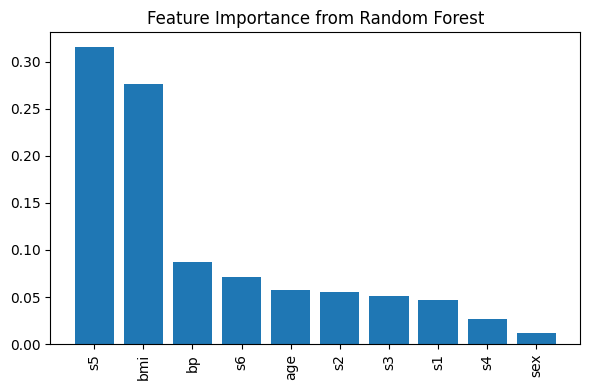

In [122]:
# Plot feature importances

plt.figure(figsize=(6, 4))
plt.bar([x[0] for x in feature_importance], [x[1] for x in feature_importance])
plt.xticks(rotation=90)
plt.title("Feature Importance from Random Forest")
plt.tight_layout()
plt.show()

In [123]:
# Print top 5 important features

print("Top 5 important features:")
for feature, importance in feature_importance[:5]:
    print(f"{feature}: {importance:.4f}")

Top 5 important features:
s5: 0.3156
bmi: 0.2762
bp: 0.0871
s6: 0.0708
age: 0.0575


In [125]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import Pipeline

In [126]:
def plot_learning_curve(estimator, X, y, title):
    train_sizes, train_scores, test_scores = learning_curve(
        estimator, X, y, cv=5, n_jobs=-1, train_sizes=np.linspace(.1, 1.0, 5))

    train_scores_mean = np.mean(train_scores, axis=1)
    test_scores_mean = np.mean(test_scores, axis=1)

    plt.figure(figsize=(4, 3))
    plt.title(title)
    plt.xlabel("Training examples")
    plt.ylabel("Score")
    plt.plot(train_sizes, train_scores_mean, 'o-', color="r", label="Training score")
    plt.plot(train_sizes, test_scores_mean, 'o-', color="g", label="Cross-validation score")
    plt.legend(loc="best")
    plt.show()

In [ ]:
# Generate sample data

np.random.seed(0)
X = np.sort(5 * np.random.rand(80, 1), axis=0)
y = np.sin(X).ravel() + np.random.normal(0, 0.1, X.shape[0])

In [ ]:
# Create models with different complexities

linear_model = LinearRegression()
poly_model_5 = Pipeline([('poly', PolynomialFeatures(degree=5)), ('linear', LinearRegression())])
poly_model_15 = Pipeline([('poly', PolynomialFeatures(degree=15)), ('linear', LinearRegression())])

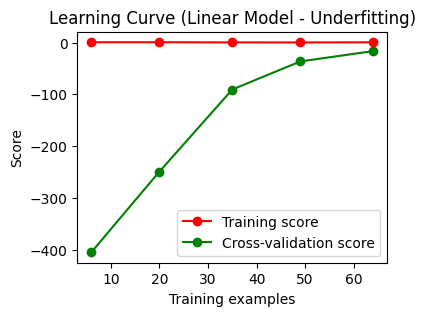

In [129]:
# Plot learning curves

plot_learning_curve(linear_model, X, y, "Learning Curve (Linear Model - Underfitting)")

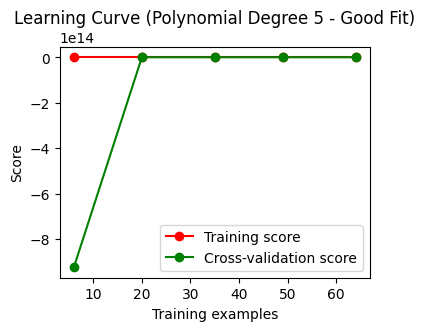

In [130]:
plot_learning_curve(poly_model_5, X, y, "Learning Curve (Polynomial Degree 5 - Good Fit)")

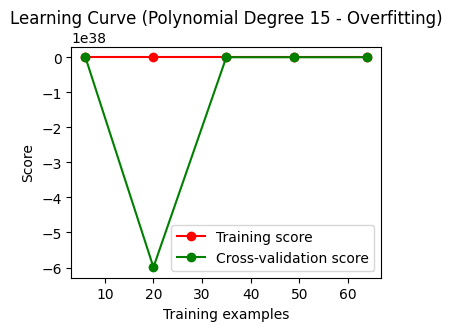

In [131]:
plot_learning_curve(poly_model_15, X, y, "Learning Curve (Polynomial Degree 15 - Overfitting)")

## Avoiding Overfitting and Underfitting

1. Use **cross-validation** to get a more robust estimate of model performance.

In [132]:
from sklearn.model_selection import cross_val_score
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestRegressor

# Assuming X and y are your features and target

rf = RandomForestRegressor(n_estimators=100, random_state=42)

X, y = load_diabetes(return_X_y=True)

# Perform RFE with cross-validation for different numbers of features

results = []
for n_features in range(1, X.shape[1] + 1):
    rfe = RFE(estimator=rf, n_features_to_select=n_features)
    scores = cross_val_score(rfe, X, y, cv=5)
    results.append((n_features, np.mean(scores), np.std(scores)))

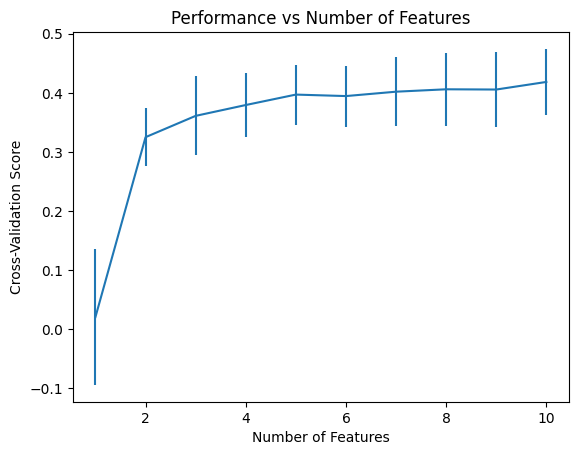

In [133]:
# Plot results

features, means, stds = zip(*results)
plt.errorbar(features, means, yerr=stds)
plt.xlabel('Number of Features')
plt.ylabel('Cross-Validation Score')
plt.title('Performance vs Number of Features')
plt.show()

2. Use **regularization techniques** to penalize model complexity.

In [134]:
from sklearn.linear_model import LassoCV

# Perform Lasso with cross-validation
lasso_cv = LassoCV(cv=5, random_state=42)
lasso_cv.fit(X, y)

print(f"Optimal alpha: {lasso_cv.alpha_}")
print(f"Number of features used: {np.sum(lasso_cv.coef_ != 0)}")

Optimal alpha: 0.003753767152691846
Number of features used: 9


3. Remove features below a certain importance threshold.

In [135]:
from sklearn.ensemble import RandomForestRegressor

rf = RandomForestRegressor(n_estimators=100, random_state=42)
rf.fit(X, y)
importances = rf.feature_importances_
threshold = 0.05  # Example threshold

In [136]:
importances

array([0.05749631, 0.01190094, 0.27624877, 0.0870851 , 0.04725057,
       0.05536752, 0.05119054, 0.02705559, 0.31562932, 0.07077534])

Selected features: ['s5', 'bmi', 'bp', 's6', 'age', 's2', 's3']


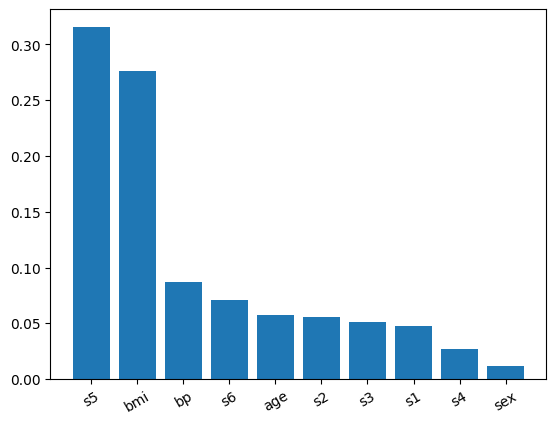

In [137]:
sorted_importances = sorted(zip(feature_names, importances), key=lambda x: x[1], reverse=True)
selected_features = [feature for feature, importance in sorted_importances if importance > threshold]
print(f"Selected features: {selected_features}")

plt.bar([x[0] for x in sorted_importances], [x[1] for x in sorted_importances])
plt.xticks(rotation=30);

### Use filter methods when:

1. **You have a very large dataset:** Filter methods are computationally efficient and can handle high-dimensional data well.

2. **You need a quick baseline:** They provide a good starting point for feature selection.

3. **You want to reduce dimensionality before applying other methods:** Filter methods can be used as a preprocessing step.

4. **You need model-agnostic feature selection:** The selected features can be used with any machine learning algorithm.

In [138]:
from sklearn.feature_selection import f_classif, SelectKBest
from sklearn.datasets import load_breast_cancer

# Load data

X, y = load_breast_cancer(return_X_y=True)

# Apply filter method

selector = SelectKBest(f_classif, k=10)
X_selected = selector.fit_transform(X, y)

print(f"Original number of features: {X.shape[1]}")
print(f"Number of features after selection: {X_selected.shape[1]}")

Original number of features: 30
Number of features after selection: 10


### Use wrapper methods when:

1. **You have moderate-sized datasets:** Wrapper methods can be computationally intensive.

2. **You want to optimize features for a specific model:** They consider the interaction between the model and features.

3. **You need to capture feature interactions:** Wrapper methods can identify useful feature combinations.

4. **You have computational resources available:** These methods often require training many models.

In [139]:
from sklearn.feature_selection import RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_iris

# Load data

X, y = load_iris(return_X_y=True)

# Apply wrapper method (RFE)

rfc = RandomForestClassifier(n_estimators=100, random_state=42)
selector = RFE(estimator=rfc, n_features_to_select=3, step=1)
X_selected = selector.fit_transform(X, y)

print(f"Original number of features: {X.shape[1]}")
print(f"Number of features after selection: {X_selected.shape[1]}")

Original number of features: 4
Number of features after selection: 3


### Use embedded methods when:

1. **You want a good balance between performance and speed:** They're generally faster than wrapper methods but more model-aware than filter methods.

2. **You're using models that inherently perform feature selection:** For example, Lasso, Ridge regression, or tree-based models.

3. **You want to consider both feature relevance and model performance:** Embedded methods often strike a good balance.

4. **You need interpretable feature importance:** Many embedded methods provide feature importance scores.


In [141]:
from sklearn.linear_model import Lasso
from sklearn.datasets import load_diabetes

# Load data

X, y = load_diabetes(return_X_y=True)

# Apply embedded method (Lasso)

lasso = Lasso(alpha=0.1)
lasso.fit(X, y)

# Get selected features

selected_features = X[:, lasso.coef_ != 0]

print(f"Original number of features: {X.shape[1]}")
print(f"Number of features after selection: {selected_features.shape[1]}")

Original number of features: 10
Number of features after selection: 7


### Use hybrid approaches when:

1. **You want to leverage the strengths of multiple methods:** For example, use a filter method for initial screening, followed by a wrapper method for fine-tuning.

2. **You need to balance computational cost and performance:** Start with faster methods and progressively use more intensive methods on a reduced feature set.

3. **You're dealing with complex datasets:** Different methods might capture different aspects of feature importance.

In [142]:
from sklearn.feature_selection import SelectKBest, f_classif, RFE
from sklearn.ensemble import RandomForestClassifier
from sklearn.datasets import load_breast_cancer

# Load data

X, y = load_breast_cancer(return_X_y=True)

# Step 1: Filter Method

filter_selector = SelectKBest(f_classif, k=20)
X_filtered = filter_selector.fit_transform(X, y)

# Step 2: Wrapper Method

rfc = RandomForestClassifier(n_estimators=100, random_state=42)
wrapper_selector = RFE(estimator=rfc, n_features_to_select=10, step=1)
X_selected = wrapper_selector.fit_transform(X_filtered, y)

print(f"Original number of features: {X.shape[1]}")
print(f"Number of features after hybrid selection: {X_selected.shape[1]}")

Original number of features: 30
Number of features after hybrid selection: 10
